# 30. Spectral ratios

The explosion airwave is impulsive and broadband, with a signal-to-noise ratio above 10 up to about 240 Hz
at the 500 samples/s stations. That makes it a good test signal for four kinds of spectral ratio:

1. **signal to noise** for every working channel (as in Artemis II notebook 42): the usable band and where
   the energy is;
2. **sensor to sensor at B14**, where three infraBSUs (CD0, CD1, CD2) recorded the same airwave: relative
   calibration, coherence and any frequency-dependent difference (enclosure or tote effects);
3. **B20 Chaparral (HDF) to infraBSU (HD1)**, outside the clipped interval and its recovery;
4. **station to station**: pressure spectra reduced to 1 km (spherical spreading and ISO 9613-1
   absorption, `ksclib.physics.atmospheric_absorption_db_per_m`), and their ratios, as a first look at
   propagation and the source spectrum.

Airwave window: 1 s before to 29 s after the predicted arrival (`cfg.airwave_speeds`). Noise window: the
240 s before the origin (the seismic waves arrive after it).

Output (`cfg.OUT_DIR / "30_spectral_ratios"`): `snr_bands.csv`, `snr_spectra.png`, `b14_sensor_ratios.csv`,
`b14_sensor_ratios.png`, `b14_summary.csv`, `b20_chaparral_ratio.csv`, `reduced_pressure_spectra.csv`,
`reduced_pressure_spectra.png`, `station_ratios.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, coherence, csd

from ksclib import physics
import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('30_spectral_ratios')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
air = cfg.airwave_speeds()
wx = cfg.weather_at_origin()[2]
PRE, POST = 1.0, 29.0
NOISE = (-250.0, -10.0)              # 240 s before the origin (seismic waves arrive after it)
SEG_S = 2.0                           # Welch segments: 2 s (0.5 Hz resolution), 50% overlap
SNR_MIN = 10.0
BANDS = [(0.5, 5), (5, 10), (10, 20), (20, 40), (40, 80), (80, 160), (160, 225)]
PRESSURE = ['1R.B20.00.HD1', '1R.B14.00.CD0', '1R.B14.00.CD1', '1R.B14.00.CD2', '1R.B29.00.CD0', '1R.B05.00.CD0']
SEISMIC = ['1R.B20.00.HHZ', '1R.B14.00.CHZ', '1R.B29.00.CHZ', '1R.B05.00.CHZ']
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
st = cfg.instrument_correct(raw)

def windows(tr):
    ta = air.travel_time_s[tr.stats.station]
    s = tr.slice(ORIGIN + ta - PRE, ORIGIN + ta + POST).data.astype(float)
    n = tr.slice(ORIGIN + NOISE[0], ORIGIN + NOISE[1]).data.astype(float)
    return s - s.mean(), n - n.mean()

def psd(x, fs):
    return welch(x, fs, nperseg=int(SEG_S * fs))
print('weather used for absorption:', {k: round(float(v), 2) for k, v in wx.items()})

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


weather used for absorption: {'temperature_c': 26.45, 'rh': 87.18, 'u': 1.94, 'v': -1.02, 'pressure_pa': 101395.0, 'n': 5.5}


## 1. Signal-to-noise spectra

SNR(f) = PSD(airwave window) / PSD(noise window). The usable band is where SNR ≥ 10; the energy share is the
fraction of excess energy (signal minus noise PSD) in each band.

,id,kind,fs,distance_km,f_low_snr10,f_high_snr10,f_peak_psd,max_snr_db,energy_0.5-5Hz_%,energy_5-10Hz_%,energy_10-20Hz_%,energy_20-40Hz_%,energy_40-80Hz_%,energy_80-160Hz_%,energy_160-225Hz_%
0,1R.B20.00.HD1,pressure,100.0,11.8,0.5,45.0,0.5,62.1,92.7,3.6,1.7,0.3,0.0,NaN,NaN
1,1R.B14.00.CD0,pressure,500.0,19.3,0.5,2.5,1.0,18.0,95.1,1.2,1.9,0.8,0.4,0.3,0.0
2,1R.B14.00.CD1,pressure,500.0,19.3,0.5,225.0,1.0,26.7,94.8,1.3,1.9,0.9,0.5,0.3,0.0
3,1R.B14.00.CD2,pressure,500.0,19.3,0.5,225.0,1.0,54.6,94.6,1.4,1.9,0.9,0.6,0.4,0.0
4,1R.B29.00.CD0,pressure,500.0,21.0,0.5,224.5,1.0,64.2,81.6,7.5,7.3,0.9,0.1,0.0,0.0
5,1R.B05.00.CD0,pressure,500.0,21.3,0.5,18.5,1.0,27.3,80.8,8.4,2.3,0.5,0.4,2.1,4.3
6,1R.B20.00.HHZ,seismic,100.0,11.8,0.5,45.0,36.0,20.6,6.7,7.3,18.4,61.6,3.0,NaN,NaN
7,1R.B14.00.CHZ,seismic,500.0,19.3,0.5,210.5,4.5,35.2,42.0,16.7,7.7,10.2,2.6,0.5,0.2
8,1R.B29.00.CHZ,seismic,500.0,21.0,0.5,225.0,5.5,58.4,8.2,56.9,19.2,6.8,0.3,0.1,0.0
9,1R.B05.00.CHZ,seismic,500.0,21.3,0.5,225.0,5.0,51.7,12.2,44.4,22.3,2.2,0.3,0.5,0.3


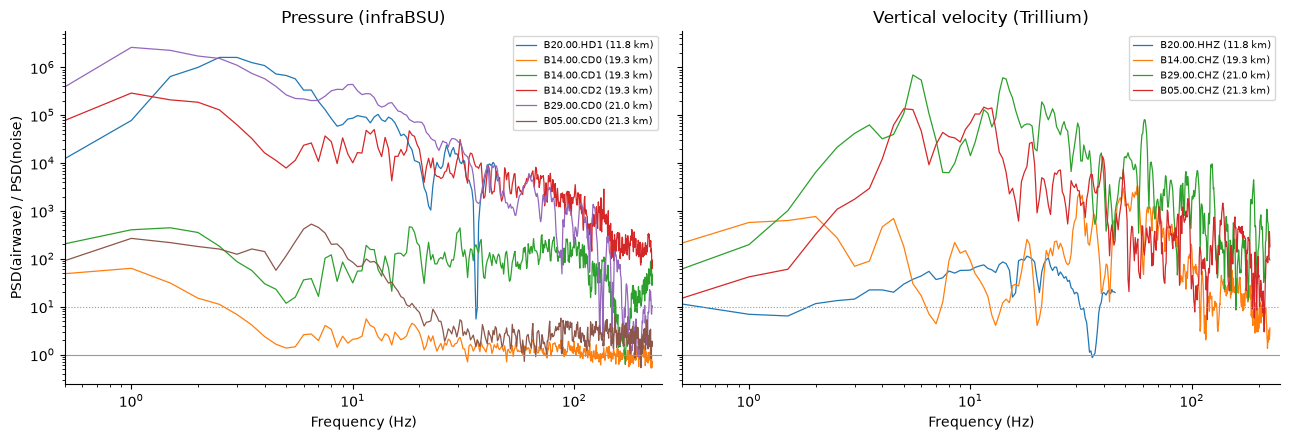

In [2]:
rows, spec = [], {}
for sid in PRESSURE + SEISMIC:
    tr = st.select(id=sid)[0]
    fs = tr.stats.sampling_rate
    s, n = windows(tr)
    f, ps = psd(s, fs)
    _, pn = psd(n, fs)
    m = (f >= 0.5) & (f <= 0.45 * fs)
    f, ps, pn = f[m], ps[m], pn[m]
    snr = ps / pn
    spec[sid] = dict(f=f, sig=ps, noise=pn, snr=snr)
    good = snr >= SNR_MIN
    ex = np.clip(ps - pn, 0, None)
    tot = np.trapezoid(ex, f)
    r = dict(id=sid, kind='pressure' if sid in PRESSURE else 'seismic', fs=fs,
             distance_km=stations.distance_km[tr.stats.station],
             f_low_snr10=f[good].min() if good.any() else np.nan, f_high_snr10=f[good].max() if good.any() else np.nan,
             f_peak_psd=f[np.argmax(ps)], max_snr_db=10 * np.log10(snr.max()))
    for lo, hi in BANDS:
        b = (f >= lo) & (f < hi)
        r[f'energy_{lo:g}-{hi:g}Hz_%'] = 100 * np.trapezoid(ex[b], f[b]) / tot if b.sum() > 1 else np.nan
    rows.append(r)
snrb = pd.DataFrame(rows)
snrb.to_csv(OUT / 'snr_bands.csv', index=False)
display(snrb.round(1))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, ids, title in ((axs[0], PRESSURE, 'Pressure (infraBSU)'), (axs[1], SEISMIC, 'Vertical velocity (Trillium)')):
    for sid in ids:
        s = spec[sid]
        ax.loglog(s['f'], s['snr'], lw=0.9, label=f"{sid.replace('1R.', '')} ({stations.distance_km[sid.split('.')[1]]:.1f} km)")
    ax.axhline(SNR_MIN, color='#999999', ls=':', lw=0.8)
    ax.axhline(1, color='#999999', lw=0.8)
    ax.set(xlabel='Frequency (Hz)', title=title, xlim=(0.5, 250))
    ax.legend(fontsize=7)
axs[0].set_ylabel('PSD(airwave) / PSD(noise)')
fig.tight_layout()
fig.savefig(OUT / 'snr_spectra.png', dpi=150, bbox_inches='tight')

## 2. Three infraBSUs at B14

PSD ratio, coherence and the H1 transfer function for each pair, in the airwave window (first 10 s, where the
signal dominates the noise at all frequencies, and the full 30 s) and in the noise window. With CD1 and CD2
coherent to high frequency, their ratio is the relative calibration; any tote or enclosure effect common
to two sensors cancels in their ratio. All three B14 infraBSUs were inside the same tote.

In [3]:
b14 = {c: st.select(id=f'1R.B14.00.{c}')[0] for c in ('CD0', 'CD1', 'CD2')}
ta = air.travel_time_s['B14']
WINS = {'airwave 0-10 s': (ORIGIN + ta - PRE, ORIGIN + ta + 9), 'airwave 0-30 s': (ORIGIN + ta - PRE, ORIGIN + ta + POST),
        'noise': (ORIGIN + NOISE[0], ORIGIN + NOISE[1])}
rows, curves = [], {}
for wname, w in WINS.items():
    d = {c: tr.slice(*w).data.astype(float) for c, tr in b14.items()}
    n = min(map(len, d.values()))
    for a, b in (('CD0', 'CD1'), ('CD0', 'CD2'), ('CD1', 'CD2')):
        x, y = d[a][:n] - d[a][:n].mean(), d[b][:n] - d[b][:n].mean()
        f, pa = psd(x, 500.0)
        _, pb = psd(y, 500.0)
        _, co = coherence(x, y, 500.0, nperseg=1000)
        _, pab = csd(x, y, 500.0, nperseg=1000)
        curves[(wname, f'{b}/{a}')] = (f, pb / pa, co, np.abs(pab) / pa)
        for lo, hi in BANDS:
            m = (f >= lo) & (f < hi)
            rows.append(dict(window=wname, pair=f'{b}/{a}', band=f'{lo:g}-{hi:g}', psd_ratio_db=10 * np.log10(np.median(pb[m] / pa[m])),
                             amp_ratio_H1=np.median(np.abs(pab[m]) / pa[m]), coherence=np.median(co[m])))
b14r = pd.DataFrame(rows)
b14r.to_csv(OUT / 'b14_sensor_ratios.csv', index=False)
display(b14r[b14r.window != 'airwave 0-30 s'].pivot_table(index=['window', 'pair'], columns='band',
        values=['psd_ratio_db', 'coherence'], sort=False).round(2))
nz = {c: tr.copy().filter('highpass', freq=0.5).slice(*WINS['noise']).data.std() for c, tr in b14.items()}
pk = {c: np.abs(tr.copy().filter('highpass', freq=0.5).slice(*WINS['airwave 0-10 s']).data).max() for c, tr in b14.items()}
print('noise rms (Pa, >0.5 Hz):', {c: round(v, 3) for c, v in nz.items()})
print('peak (Pa, >0.5 Hz):', {c: round(v, 1) for c, v in pk.items()})
q = b14r[(b14r.window == 'airwave 0-10 s') & (b14r.pair == 'CD2/CD1') & b14r.band.isin(['0.5-5', '5-10', '10-20', '20-40'])]
print(f'amplitude ratio CD2/CD1 from PSD, 0.5-40 Hz: {10 ** (q.psd_ratio_db.mean() / 20):.3f}')
f, r, co, _ = curves[('airwave 0-10 s', 'CD2/CD1')]
hf = (f >= 100) & (f <= 240)
k = np.argmax(r[hf])
print(f'CD2/CD1 above 100 Hz: peak {10 * np.log10(r[hf][k]):+.1f} dB at {f[hf][k]:.1f} Hz '
      f'(coherence {co[hf][k]:.2f}); minimum {10 * np.log10(r[hf].min()):+.1f} dB at {f[hf][np.argmin(r[hf])]:.1f} Hz')
co_med = pd.Series(co).rolling(5, center=True, min_periods=1).median().to_numpy()   # robust to single-bin dips
below = f[(f >= 0.5) & (co_med < 0.98)]
f_coh = below.min() if len(below) else f.max()
pd.DataFrame([dict(amp_ratio_CD2_CD1=10 ** (q.psd_ratio_db.mean() / 20), resonance_peak_hz=f[hf][k],
                   resonance_peak_db=10 * np.log10(r[hf][k]), resonance_min_hz=f[hf][np.argmin(r[hf])],
                   resonance_min_db=10 * np.log10(r[hf].min()), coherence_098_up_to_hz=f_coh,
                   noise_CD0_Pa=nz['CD0'], noise_CD1_Pa=nz['CD1'], noise_CD2_Pa=nz['CD2'],
                   peak_CD0_Pa=pk['CD0'], peak_CD1_Pa=pk['CD1'], peak_CD2_Pa=pk['CD2'])]).to_csv(OUT / 'b14_summary.csv', index=False)
print(f'CD2/CD1 coherence (5-bin running median) >= 0.98 up to {f_coh:.0f} Hz')

psd_ratio_db                                     \
band                          0.5-5   5-10  10-20  20-40  40-80 80-160   
window         pair                                                      
airwave 0-10 s CD1/CD0         2.01   1.38   1.35   1.12  -0.41  -2.76   
               CD2/CD0        -0.20  -0.83  -0.87  -1.08  -1.26  -4.63   
               CD2/CD1        -2.21  -2.21  -2.20  -2.19  -1.29  -1.45   
noise          CD1/CD0       -10.09 -12.17 -15.81 -20.54 -23.10 -25.58   
               CD2/CD0       -40.16 -41.62 -41.13 -40.54 -39.66 -38.12   
               CD2/CD1       -29.52 -29.09 -25.76 -19.97 -16.61 -12.38   

                               coherence                                 \
band                   160-225     0.5-5  5-10 10-20 20-40 40-80 80-160   
window         pair                                                       
airwave 0-10 s CD1/CD0  -10.12      0.95  0.83  0.87  0.76  0.61   0.37   
               CD2/CD0  -13.75      0.95  0.82  0.87  0.76  0.60   0.37   
               CD2/CD1   -3.79      1.00  1.00  1.00  1.00  1.00   1.00   
noise          CD1/CD0  -27.21      0.01  0.00  0.00  0.00  0.00   0.00   
               CD2/CD0  -42.03      0.00  0.01  0.00  0.00  0.00   0.00   
               CD2/CD1  -14.77      0.20  0.13  0.03  0.01  0.01   0.04   

                                
band                   160-225  
window         pair             
airwave 0-10 s CD1/CD0    0.09  
               CD2/CD0    0.09  
               CD2/CD1    0.99  
noise          CD1/CD0    0.00  
               CD2/CD0    0.00  
               CD2/CD1    0.01

noise rms (Pa, >0.5 Hz): {'CD0': np.float64(4.713), 'CD1': np.float64(1.152), 'CD2': np.float64(0.06)}
peak (Pa, >0.5 Hz): {'CD0': np.float64(261.7), 'CD1': np.float64(338.0), 'CD2': np.float64(269.6)}
amplitude ratio CD2/CD1 from PSD, 0.5-40 Hz: 0.776
CD2/CD1 above 100 Hz: peak +10.1 dB at 170.5 Hz (coherence 0.82); minimum -12.9 dB at 233.5 Hz
CD2/CD1 coherence (5-bin running median) >= 0.98 up to 160 Hz


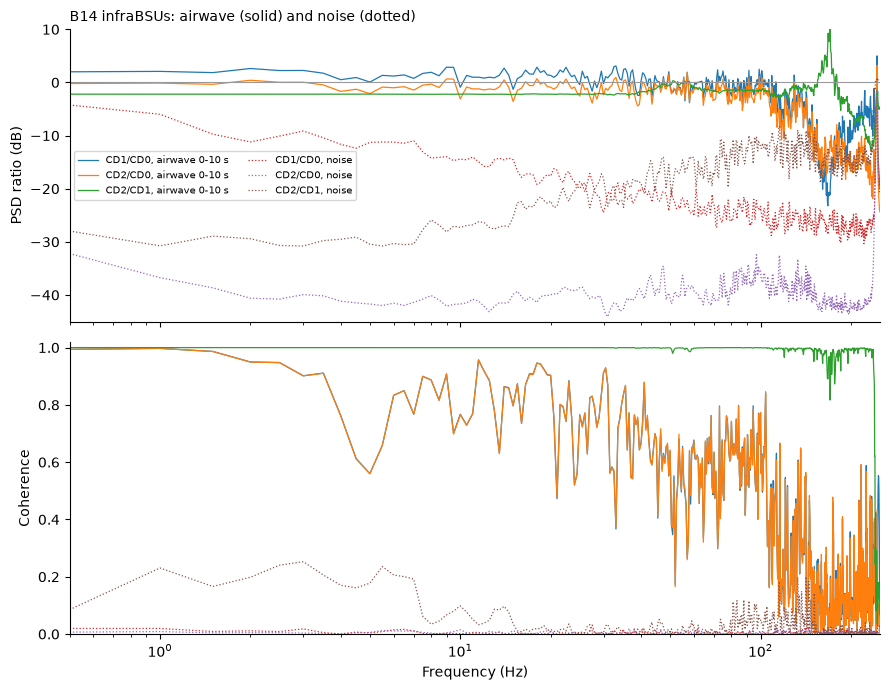

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for (wname, pair), (f, r, co, h1) in curves.items():
    if wname == 'airwave 0-30 s':
        continue
    ls = '-' if wname.startswith('airwave') else ':'
    axs[0].semilogx(f[1:], 10 * np.log10(r[1:]), ls, lw=0.9, label=f'{pair}, {wname}')
    axs[1].semilogx(f[1:], co[1:], ls, lw=0.9)
axs[0].axhline(0, color='#999999', lw=0.8)
axs[0].set(ylabel='PSD ratio (dB)', ylim=(-45, 10))
axs[1].set(ylabel='Coherence', xlabel='Frequency (Hz)', ylim=(0, 1.02), xlim=(0.5, 250))
axs[0].legend(fontsize=7, ncol=2)
axs[0].set_title('B14 infraBSUs: airwave (solid) and noise (dotted)', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(OUT / 'b14_sensor_ratios.png', dpi=150, bbox_inches='tight')

## 3. B20 Chaparral (HDF) to infraBSU (HD1)

Outside the clipped interval and the overload recovery (notebook 22): the late coda (60–120 s after the
origin) and the pre-event noise. A flat ratio means the two responses have the same shape and differ only in
scale (notebook 22 found HDF/HD1 ≈ 0.05).

HDF_over_HD1_H1            coherence       
window   coda 60-120 s  noise coda 60-120 s  noise
band                                              
0.25-1           0.045  0.054         0.824  0.728
1-5              0.050  0.056         0.829  0.403
10-20            0.086  0.060         0.674  0.441
20-45            0.147  0.061         0.429  0.188
5-10             0.056  0.054         0.837  0.464

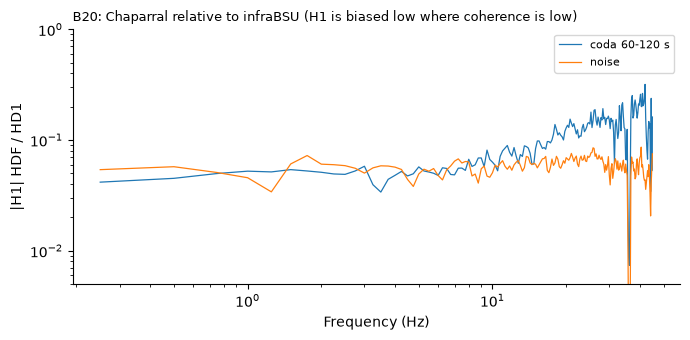

In [5]:
ddf, dd1 = st.select(id='1R.B20.00.HDF')[0], st.select(id='1R.B20.00.HD1')[0]
rows = []
fig, ax = plt.subplots(figsize=(7, 3.5))
for wname, w in (('coda 60-120 s', (ORIGIN + 60, ORIGIN + 120)), ('noise', (ORIGIN - 200, ORIGIN - 20))):
    x, y = dd1.slice(*w).data.astype(float), ddf.slice(*w).data.astype(float)
    n = min(len(x), len(y)); x, y = x[:n] - x[:n].mean(), y[:n] - y[:n].mean()
    f, pxy = csd(x, y, 100.0, nperseg=400)
    _, pxx = welch(x, 100.0, nperseg=400)
    _, co = coherence(x, y, 100.0, nperseg=400)
    h1 = np.abs(pxy) / pxx
    m = (f >= 0.25) & (f <= 45)
    ax.semilogx(f[m], h1[m], lw=0.9, label=wname)
    for lo, hi in ((0.25, 1), (1, 5), (5, 10), (10, 20), (20, 45)):
        b = (f >= lo) & (f < hi)
        rows.append(dict(window=wname, band=f'{lo:g}-{hi:g}', HDF_over_HD1_H1=np.median(h1[b]), coherence=np.median(co[b])))
ax.set(xlabel='Frequency (Hz)', ylabel='|H1| HDF / HD1', yscale='log', ylim=(0.005, 1))
ax.legend(fontsize=8)
ax.set_title('B20: Chaparral relative to infraBSU (H1 is biased low where coherence is low)', loc='left', fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'b20_chaparral_ratio.png', dpi=150, bbox_inches='tight')
chap = pd.DataFrame(rows)
chap.to_csv(OUT / 'b20_chaparral_ratio.csv', index=False)
display(chap.pivot(index='band', columns='window', values=['HDF_over_HD1_H1', 'coherence']).round(3))

## 4. Pressure spectra reduced to 1 km, and station ratios

Each pressure spectrum (amplitude spectral density, airwave window) is multiplied by $r/1\,\mathrm{km}$
(spherical spreading) and by $10^{\alpha(f) r / 20}$ (ISO 9613-1 absorption for the weather at the origin).
If propagation were spherical and still-air, the reduced spectra would coincide. B14 uses CD2, the
lowest-noise infraBSU there. Ratios are taken relative to B29 (quietest station) for the 500 samples/s
stations, and relative to B20 up to 45 Hz.

These are not yet corrected for the relative calibration of the infraBSUs (from the Artemis II papers),
which shifts each curve by a constant.

band,0.5-5,5-10,10-20,20-40,40-80,80-160,160-225
ratio,,,,,,,
B05/B20,-0.6,5.9,0.9,NaN,NaN,NaN,NaN
B05/B29,-1.2,-0.4,-5.8,NaN,NaN,NaN,NaN
B14/B20,-4.1,-2.3,1.0,6.1,6.8,NaN,NaN
B14/B29,-4.7,-8.0,-5.6,0.6,6.8,9.4,9.9
B29/B20,0.2,4.7,7.2,4.9,3.6,NaN,NaN


absorption over each path (dB) at 20/100/200 Hz: {'B20': [0.07, 0.36, 0.36], 'B14': [0.12, 2.84, 10.96], 'B29': [0.13, 3.09, 11.91], 'B05': [0.13, 3.14, 12.09]}


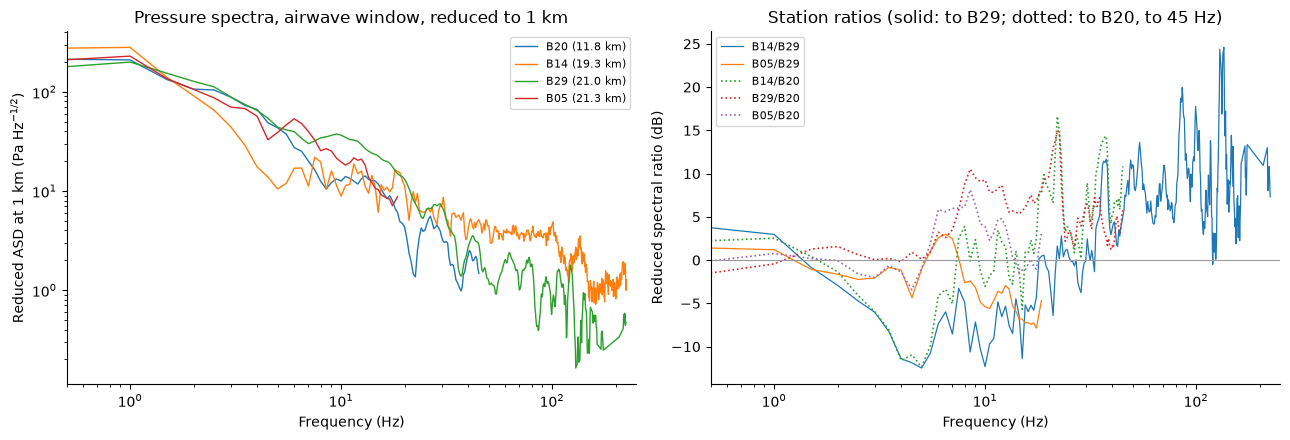

In [6]:
RED = {'B20': '1R.B20.00.HD1', 'B14': '1R.B14.00.CD2', 'B29': '1R.B29.00.CD0', 'B05': '1R.B05.00.CD0'}
red = {}
for sta, sid in RED.items():
    s = spec[sid]
    r = air.distance_m[sta]
    alpha = physics.atmospheric_absorption_db_per_m(s['f'], wx['temperature_c'], wx['rh'], wx['pressure_pa'])
    asd = np.sqrt(s['sig'])
    asd_red = asd * (r / 1000.0) * 10 ** (alpha * r / 20)
    good = s['snr'] >= SNR_MIN
    red[sta] = dict(f=s['f'], asd=asd_red, good=good, absorption_db=alpha * r)
pd.DataFrame([dict(station=k, f_hz=fi, asd_reduced_Pa_per_rtHz=a, snr_ok=g, absorption_db=ab)
              for k, d in red.items() for fi, a, g, ab in zip(d['f'], d['asd'], d['good'], d['absorption_db'])]
             ).to_csv(OUT / 'reduced_pressure_spectra.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for sta, d in red.items():
    g = d['good']
    axs[0].loglog(d['f'][g], d['asd'][g], lw=1, label=f"{sta} ({stations.distance_km[sta]:.1f} km)")
axs[0].set(xlabel='Frequency (Hz)', ylabel='Reduced ASD at 1 km (Pa Hz$^{-1/2}$)', xlim=(0.5, 250),
           title='Pressure spectra, airwave window, reduced to 1 km')
axs[0].legend(fontsize=8)
rows = []
for ref, others, fmax in (('B29', ['B14', 'B05'], 225.0), ('B20', ['B14', 'B29', 'B05'], 45.0)):
    for sta in others:
        a, b = red[sta], red[ref]
        fb = b['f']
        ai = np.interp(fb, a['f'], a['asd'])
        gi = np.interp(fb, a['f'], a['good'].astype(float)) > 0.5
        m = gi & b['good'] & (fb <= fmax)
        ratio_db = 20 * np.log10(ai / b['asd'])
        if ref == 'B29':
            axs[1].semilogx(fb[m], ratio_db[m], lw=0.9, label=f'{sta}/{ref}')
        else:
            axs[1].semilogx(fb[m], ratio_db[m], ':', lw=1.2, label=f'{sta}/{ref}')
        for lo, hi in BANDS:
            bm = m & (fb >= lo) & (fb < hi)
            if bm.any():
                rows.append(dict(ratio=f'{sta}/{ref}', band=f'{lo:g}-{hi:g}', median_db=np.median(ratio_db[bm])))
axs[1].axhline(0, color='#999999', lw=0.8)
axs[1].set(xlabel='Frequency (Hz)', ylabel='Reduced spectral ratio (dB)', xlim=(0.5, 250),
           title='Station ratios (solid: to B29; dotted: to B20, to 45 Hz)')
axs[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'reduced_pressure_spectra.png', dpi=150, bbox_inches='tight')
sr = pd.DataFrame(rows)
sr.to_csv(OUT / 'station_ratios.csv', index=False)
display(sr.pivot(index='ratio', columns='band', values='median_db')[[f'{lo:g}-{hi:g}' for lo, hi in BANDS if f'{lo:g}-{hi:g}' in sr.band.values]].round(1))
print('absorption over each path (dB) at 20/100/200 Hz:',
      {k: [round(float(np.interp(fq, d['f'], d['absorption_db'])), 2) for fq in (20, 100, 200)] for k, d in red.items()})

## What this shows

* **Signal to noise.** The airwave exceeds the noise by more than 10 (in PSD) from 0.5 Hz to 225 Hz at the
  quiet infraBSUs (B14 CD1/CD2, B29 CD0), and up to 45 Hz at B20 (100 samples/s). The noisy CD0s at B14 and
  B05 (about 4.7 Pa rms above 0.5 Hz) limit them to 2.5 and 18.5 Hz. 81–95% of the pressure energy is
  below 5 Hz, peaking at 0.5–1 Hz. The ground motion's energy sits at the site resonances (4.5–5.5 Hz at
  B14, B29 and B05). At B20, 62% falls at 20–40 Hz, which is machinery-tone contamination rather than
  signal.
* **B14 infraBSUs.**
  * CD1 and CD2 record the airwave identically: coherence 1.00 from 0.5 to about 200 Hz, with a constant
    amplitude ratio CD2/CD1 = 0.776 (−2.2 dB) up to 40 Hz. That is a relative calibration difference of
    22%, larger than the ±13% in the peaks; the Artemis II calibration should settle which is right.
  * Above 100 Hz the two differ: CD2/CD1 peaks at +10 dB near 170 Hz and drops to −13 dB near 234 Hz.
    All three sensors sat in the same tote, so this is a resonance of one sensor's own inlet (capillary
    tube, nipple or fitting) that the other lacks, not a tote effect. It matters only for the highest
    frequencies.
  * CD0 agrees in level with CD2 to within 1 dB below 40 Hz, but its noise is 40 dB higher and its
    coherence with the others drops above about 40 Hz.
  * The three sensors have very different noise (CD0 4.7, CD1 1.2, CD2 0.06 Pa rms above 0.5 Hz) yet the
    same airwave. They shared one tote, so the difference is not the tote's exposure to wind: it lies in
    each sensor's inlet (tube routing, leaks) or electronics.
  * CD0's coherence also dips at 4–5 Hz, where the ground resonates (notebook 28), which may mean CD0
    feels ground vibration.
* **Tote effects.** All three B14 infraBSUs were in the same tote, so a tote effect is common to them and
  cancels in their ratios; none of the differences above is a tote effect. With no free-field Gem at this
  event, the tote effect itself has to come from the Artemis II enclosure comparison.
* **B20 Chaparral.** Outside the clipping, HDF/HD1 is flat at 0.050–0.056 from 0.25 to 45 Hz in the noise,
  and 0.045–0.056 below 10 Hz in the coda. The two responses have the same shape and differ only in scale
  (the rise above 10 Hz in the coda comes with low coherence). That scale is the M25 fault found in
  notebook 32: about 0.02 V/Pa at the time, against 0.4 V/Pa in normal operation.
* **Propagation.** Reduced to 1 km (spherical spreading plus ISO 9613-1 absorption, at most 12 dB at
  200 Hz over 21 km), the four pressure spectra agree to about ±3 dB below 4 Hz. Spherical spreading
  therefore holds for the dominant low frequencies. The station-to-station differences are at higher
  frequencies:
  * B29 is 5–7 dB above B20 at 5–20 Hz.
  * B14 is 5–8 dB below B29 at 5–20 Hz and 7–10 dB above it at 40–225 Hz.

  The slower-than-1/r fall-off of the *peak* pressures (notebook 22) is carried by these higher
  frequencies, which a 100 samples/s B20 also under-records. The infraBSU calibration corrections are still
  to be applied.